<span style="margin: 0; font-size: 25px; font-weight: 500">Short-Latency Hand Movement Classification based on Surface-EMG Spectrogram with PCA</span>
<br>
<span style="margin: 0; font-size: 16px">Xiaolong Zhai, Beth Jelfs, Rosa H. M. Chan, Chung Tin</span>

<span style="margin: 0; font-size: 15px;">implemented for</span>
<br>
<span style="margin: 0; font-size: 18px;">Research Paper Implementation</span>
<br>
<span style="margin: 0; font-size: 15px;">BM4152 - Bio-Signal Processing</span>
<br>

<span style="margin: 0; font-size: 15px;">by Fernando D. S. (220163X) and Udugamasooriya P. H. J. (220658U)</span>

<hr>

### 1. Introduction and Preliminaries

In this paper, the authors make use of the Ninapro DB2 dataset. It contains EMG data collected from 40 subjects performing 49 different hand movements.

The 49 movements are put into three broad categories as follows:
1. E1 - basic movements of fingers (and wrist)
2. E2 - grasping and functional movements
3. E3 - force patterns

The entire DB2 dataset may be accessed [here](https://ninapro.hevs.ch/instructions/DB2.html). The page contains 40 `.zip` files, named `s1.zip` through `s40.zip`, each one containing the data collected from a single subject.
Each `.zip` file contains three files, named `SX_E1_A1.mat`, `SX_E2_A1.mat` and `SX_E3_A1.mat`, where `X` is the subject index. The second portion of the filename identifies the category of movements contained within it.

In this notebook, we will only utilize 17 movements in category E1 (18 including rest). We will inspect the contents of `S2_E1_A1.mat` to understand how the data is structured.

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sklearn
import random
import pymatreader # to read .mat files

subject_data = pymatreader.read_mat('../DB2_s2/S2_E1_A1.mat')

In [78]:
print (subject_data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'emg', 'acc', 'stimulus', 'glove', 'inclin', 'subject', 'exercise', 'repetition', 'restimulus', 'rerepetition'])


In [79]:
print (
    subject_data['emg'].shape,
    subject_data['stimulus'].shape,
    subject_data['repetition'].shape,
    subject_data['restimulus'].shape,
    subject_data['rerepetition'].shape
)

print (
    np.unique(subject_data['stimulus']),
    np.unique(subject_data['repetition'])
)

(1803711, 12) (1803711,) (1803711,) (1803711,) (1803711,)
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17] [0 1 2 3 4 5 6]


`subject_data['emg']` is a $1803711 \times 12$ matrix. Each column corresponds to a single EMG channel, and each row is a single sample. The sampling frequency is given to be $2\text{ kHz}$.

`subject_data['stimulus']` identifies each sample with the particular movement being performed by the subject, and is a number between 0 and 17. `subject_data['repetition']` identifies each sample with which repetition of the corresponding movement it is associated with, and is a number between 0 and 6 (0 being a neutral value, and 1 through 6 identifying the first through sixth repetitions).

`subject_data['restimulus']` and `subject_data['rerepetition']` are similar, but contain relabeled values, by accounting for delays and discrepancies that the subject may have shown in copying the instructions given.

In [80]:
fs = 2000 # sampling frequency

# Construct an array with strings identifying each movement index
movement_names = [
    "rest",
    "thumb up",
    "extension of index and middle, flexion of others",
    "flexion of ring and pinky, extension of others",
    "thumb opposing base of pinky",
    "abduction of all fingers",
    "fingers flexed together in fist",
    "pointing index",
    "adduction of extended fingers",
    "wrist supination (axis: middle finger)",
    "wrist pronation (axis: middle finger)",
    "wrist supination (axis: little finger)",
    "wrist pronation (axis: little finger)",
    "wrist flexion",
    "wrist extension",
    "wrist radial deviation",
    "wrist ulnar deviation",
    "wrist extension with closed hand"
]

We will implement a function to obtain the entire EMG signal corresponding to a particular repetition of a particular movement, from each of the 12 channels, from a specified subject. Because there are disproportionately many repetitions of the 'rest' movement, we implement a different function to randomly extract rest signals instead, to keep the data balanced (as described in the paper).

In [81]:
def extract_rest_indices(subject_data, num_repetitions, random_seed):
    """
        Randomly extracts the start and end indices of where the specified number of rest movements can be found, and modifies subject_data by adding new keys.
    
        Parameters
        ----------
        subject_data : dict
            dictionary returned by pymatreader after reading the relevant .mat file corresponding to a subject

        num_repetitions : number
            extracts this many repetitions of the rest movement
        
        random_seed : number
            seed for a random number generator to pick random rest samples, ideally subject-specific

        Returns
        -------
        None
    """

    random.seed(random_seed)

    for prefix in ['re', '']:
        movement_ids = subject_data[prefix + 'stimulus']

        # All samples where movement_ids == 0 correspond to a rest
        rests = (movement_ids == 0).astype(int)

        # Pad the beginning and end with 0s (we begin and end with a non-rest, so any rest, if present, must be strictly inside the array), to eliminate edge cases
        rests_padded = np.pad(rests, pad_width=1, mode='constant', constant_values=0)

        # Note we drop the first and last index, to avoid possible long rest margins at the beginning and end
        rest_start_indices = np.where(np.diff(rests_padded) == 1)[0][1 : -1]
        rest_end_indices = np.where(np.diff(rests_padded) == -1)[0][1 : -1]

        random_indices = random.sample(range(len(rest_start_indices)), num_repetitions)

        subject_data[prefix + 'reststart'] = rest_start_indices[random_indices]
        subject_data[prefix + 'restend'] = rest_end_indices[random_indices]

def emg_of_movement(subject_data, movement_id, repetition_num, corrected=True):
    """
        Extracts the samples corresponding to a specified movement index and repetition number from all 12 channels.
    
        Parameters
        ----------
        subject_data : dict
            dictionary returned by pymatreader after reading the relevant .mat file corresponding to a subject

        movement_id : number
            between 0 and 17, identifying the movement

        repetition_num : number
            between 1 and 6, identifying which repetition in particular to extract
    
        corrected : boolean
            if True, uses the revised labels to extract the signal; otherwise uses raw labels
        
        Returns
        -------
        n x 12 array
            where n is the number of samples associated with the specified repetition of the specified movement, and the second dimension corresponds to each channel
            
    """
    
    if (movement_id < 0) or (movement_id > 17):
        print ("Invalid Movement ID")
        return

    if (repetition_num < 1) or (repetition_num > 6):
        print ("Invalid Repetition Number")
        return

    emg_data = subject_data['emg']

    # Extract rests separately
    if (movement_id == 0):
        if corrected:
            start_index = subject_data['rereststart'][repetition_num - 1]
            end_index = subject_data['rerestend'][repetition_num - 1]
        else:
            start_index = subject_data['reststart'][repetition_num - 1]
            end_index = subject_data['restend'][repetition_num - 1]
        return emg_data[start_index : end_index, :]

    if corrected:
        movement_ids = subject_data['restimulus']
        repetition_nums = subject_data['rerepetition']
    else:
        movement_ids = subject_data['stimulus']
        repetition_nums = subject_data['repetition']
        
    return emg_data[(movement_ids == movement_id) & (repetition_nums == repetition_num), :]

We will implement another function to construct segments from a provided set of EMG samples from each channel.

In [82]:
def construct_segments(emg_data, num_samples, step_samples):
    """
        Constructs segments of consecutive samples from the provided EMG data from all (12) channels.
    
        Parameters
        ----------
        emg_data : array
            an n x N array, n samples obtained from each of N channels (the dataset here has N = 12 channels in total)

        num_samples : number
            number of consecutive samples to include in a segment from each channel
    
        step_samples : number
            number of samples to skip forward from the start of the current segment, to form the next
        
        Returns
        -------
        n x N array
            where n is the number of samples associated with the specified repetition of the specified movement, and the second dimension corresponds to each channel
    """

    n, _ = emg_data.shape # total number of samples per channel

    if (num_samples > n) or (num_samples <= 0):
        print ("Invalid Number of Samples")
        return []

    if (step_samples <= 0):
        print ("Invalid Step")
        return []
    
    segments = []

    for i in range(0, n - num_samples + 1, step_samples):
        segments.append(emg_data[i : i + num_samples, :])

    return segments

Next, we implement a function to compute the normalized spectrogram of a provided signal segment from each channel. We also implement a function to compute the raw, un-normalized spectrogram, for use in training to determine the normalizing limits.

In [83]:
def normalized_spectrograms_vector(segment, normalizer, upper_cutoff_freq_index, **spectrogram_kwargs):
    """
        Computes the normalized spectrogram of the signal segment provided from each channel, and returns a vector with all spectrograms concatenated.

        Parameters
        ----------
        segment : array
            an n x N array, where n is the number of samples in the segment and N is the number of channels

        normalizer : function
            a function to normalize the spectrogram computed per channel

        upper_cutoff_freq_index : number
            only the frequency bins starting from index 0 to this index will be retained from the spectrogram computed
            
        **spectrogram_kwargs : dictionary
            keyword arguments required by scipy.signal.spectrogram
    
        Returns
        -------
        array
            a flattened and normalized vector of all spectrograms concatenated, whose dimensions depend on the cutoff frequency and other parameters set for scipy.signal.spectrogram
    """
    
    spectrogram_vectors = []
    channel_index = 0

    for channel in segment.T:
        _, _, spectrogram = scipy.signal.spectrogram(channel, **spectrogram_kwargs)

        # Retain only the specified frequency bins
        spectrogram = spectrogram[:upper_cutoff_freq_index, :]

        # Normalize and flatten to a vector
        spectrogram_vector = normalizer(spectrogram.flatten(), channel_index)
        channel_index += 1

        spectrogram_vectors.append(spectrogram_vector)

    return np.concatenate(spectrogram_vectors)

def raw_spectrogram_vector(segment, upper_cutoff_freq_index, **spectrogram_kwargs):
    """
        Computes the spectrogram of the signal segment provided from each channel and returns a flattened vector for each channel.

        Parameters
        ----------
        segment : array
            an n x N array, where n is the number of samples in the segment and N is the number of channels

        upper_cutoff_freq_index : number
            only the frequency bins starting from index 0 to this index will be retained from the spectrogram computed
            
        **spectrogram_kwargs : dictionary
            keyword arguments required by scipy.signal.spectrogram
    
        Returns
        -------
        array
            a list of vectors, each vector being the flattened spectrogram computed for a channel
    """

    spectrogram_vectors = []

    for channel in segment.T:
        _, _, spectrogram = scipy.signal.spectrogram(channel, **spectrogram_kwargs)

        # Retain only the specified frequency bins, and flatten to a vector
        spectrogram = spectrogram[:upper_cutoff_freq_index, :].flatten()

        spectrogram_vectors.append(spectrogram)

    return spectrogram_vectors

To compare the performance of using the spectrogram for classification, we also implement a function to compute the RMS of a signal segment provided from each channel, and attempt to classify using RMS as well.

In [84]:
def RMS(segment):
    """
        Computes the RMS of the signal segment provided from each channel.

        Parameters
        ----------
        segment : array
            an n x N array, where n is the number of samples in the segment and N is the number of channels
    
        Returns
        -------
        1 x N array
            containing the RMS value of the segment from each channel
            
    """

    return np.array([
        np.sqrt(np.mean(channel ** 2)) for channel in segment.T
    ])

### 2. Training and Testing

We will now implement functions to prepare data for training and testing a PCA transformer and classifier.

We train with the 1<sup>st</sup>, 3<sup>rd</sup>, 4<sup>th</sup>, and 6<sup>th</sup> repetitions of each movement by each user, and test on the remaining repetitions.

First, we construct the training and testing data sets.

In [89]:
def prepare_data(subject_id):
    """
        Reads the .mat file with data corresponding to the specified subject, and randomly chooses some repetitions of the rest movement for training and testing purposes.

        Parameters
        ----------
        subject_id : number
            between 1 and 40, identifying the subject
    
        Returns
        -------
        dict
            the same dictionary returned by pymatreader.read_mat, with additional keys
    """

    subject_data = pymatreader.read_mat(f'../DB2_s{subject_id}/S{subject_id}_E1_A1.mat')
    extract_rest_indices(subject_data, 6, subject_id + 5) # as there are 6 repetition of each movement

    return subject_data
    

def spectrogram_dataset_for_subject(subject_data):
    """
        Extracts data from the specified subject and returns a training and testing data set constructed using spectrograms, along with a function for normalizing data.

        Parameters
        ----------
        subject_data : dict
            a dictionary with details of the subject
    
        Returns
        -------
        (normalizer, X_train, y_train, X_test, y_test) : tuple
            - normalizer:   function to which a raw flattened spectrogram from a channel can be passed to normalize it
            - X_train:      list of spectrogram vectors for training
            - y_train:      list of labels identifying the movement class corresponding to each entry in X_train
            - X_test:       similar to X_train, but with test data
            - y_test:       similar to y_train, but with test labels
    """
    
    X_train_raw, X_train, y_train = [], [], []
    X_test_raw, X_test, y_test = [], [], []
    
    for movement_id in range(0, 18):
        for repetition_num in range(1, 7):

            full_emg_data = emg_of_movement(subject_data, movement_id, repetition_num)
            segments = construct_segments(full_emg_data, 400, 200)

            # For now, we append per-channel flattened spectrograms. Later we will normalize and concatenate them.
            if (repetition_num == 2 or repetition_num == 5):
                for segment in segments:
                    X_test_raw.append(raw_spectrogram_vector(
                        segment, 95,
                        fs=fs,
                        window='hamming',
                        nperseg=256,
                        noverlap=184,
                        nfft=256,
                        detrend=False
                    ))
                    y_test.append(movement_id)
            else:
                for segment in segments:
                    X_train_raw.append(raw_spectrogram_vector(
                        segment, 95,
                        fs=fs,
                        window='hamming',
                        nperseg=256,
                        noverlap=184,
                        nfft=256,
                        detrend=False
                    ))
                    y_train.append(movement_id)

    X_train_raw = np.array(X_train_raw)

    # Compute 1st and 99th percentiles for normalization as described 
    num_train_segments, num_channels, _ = X_train_raw.shape
    min_values = [np.percentile(X_train_raw[:, i, :], 1) for i in range(num_channels)]
    max_values = [np.percentile(X_train_raw[:, i, :], 99) for i in range(num_channels)]

    # Define a function for normalization, taking care to clip values that land outside the percentiles
    def normalizer(spectrogram_vector, channel_index):
        """
            Normalizes (and clips to 0 and 1) the data in a flattened spectrogram from a given channel.
    
            Parameters
            ----------
            spectrogram_vector : array
                a flattened vector spectrogram vector obtained from a single channel

            channel_index : number
                a number identifying the channel from which the spectrogram has been computed
        
            Returns
            -------
            vector
                the same flat spectrogram vector, but with its entries scaled and clipped to lie within 0 and 1
        """
        
        scaled = (spectrogram_vector - min_values[channel_index]) / (max_values[channel_index] - min_values[channel_index])
        return np.clip(scaled, 0, 1)

    # Prepare the data in the format expected for training, by normalizing each spectrogram and concatenating them
    for segment_index in range(num_train_segments):
        train_vector = []

        for channel_index in range(num_channels):
            spectrogram_vector = X_train_raw[segment_index, channel_index, :]

            train_vector.append(normalizer(spectrogram_vector, channel_index))

        X_train.append(np.concatenate(train_vector))

    X_train = np.array(X_train)
    y_train = np.array(y_train)

    # Repeat with test data
    X_test_raw = np.array(X_test_raw)
    num_test_segments, _, _ = X_test_raw.shape

    for segment_index in range(num_test_segments):
        test_vector = []

        for channel_index in range(num_channels):
            spectrogram_vector = X_test_raw[segment_index, channel_index, :]

            test_vector.append(normalizer(spectrogram_vector, channel_index))

        X_test.append(np.concatenate(test_vector))

    X_test = np.array(X_test)
    y_test = np.array(y_test)

    return (normalizer, X_train, y_train, X_test, y_test)

def rms_dataset_for_subject(subject_data):
    """
        Extracts data from the specified subject and returns a training and testing data set constructed using the RMS as the feature, along with a function for normalizing data.

        Parameters
        ----------
        subject_data : dict
            a dictionary with details of the subject
    
        Returns
        -------
        (normalizer, X_train, y_train, X_test, y_test) : tuple
            - normalizer:   function to which an RMS vector can be passed to normalize it
            - X_train:      list of RMS vectors for training
            - y_train:      list of labels identifying the movement class corresponding to each entry in X_train
            - X_test:       similar to X_train, but with test data
            - y_test:       similar to y_train, but with test labels
    """
    
    X_train, y_train = [], []
    X_test, y_test = [], []
    
    for movement_id in range(0, 18):
        for repetition_num in range(1, 7):

            full_emg_data = emg_of_movement(subject_data, movement_id, repetition_num)
            segments = construct_segments(full_emg_data, 400, 200)

            # For now, we append per-channel flattened spectrograms. Later we will normalize and concatenate them.
            if (repetition_num == 2 or repetition_num == 5):
                for segment in segments:
                    X_test.append(RMS(segment))
                    y_test.append(movement_id)
            else:
                for segment in segments:
                    X_train.append(RMS(segment))
                    y_train.append(movement_id)

    X_train = np.array(X_train)

    # Compute 1st and 99th percentiles for normalization as described
    num_train_segments, num_channels = X_train.shape
    min_values = np.array([np.percentile(X_train[:, i], 1) for i in range(num_channels)])
    max_values = np.array([np.percentile(X_train[:, i], 99) for i in range(num_channels)])

    # Define a function for normalization, taking care to clip values that land outside the percentiles
    def normalizer(rms_vector):
        """
            Normalizes (and clips to 0 and 1) a given RMS vector.
    
            Parameters
            ----------
            rms_vector : array
                RMS vector computed from a segment
        
            Returns
            -------
            vector
                the same RMS vector, but with its entries scaled and clipped to lie within 0 and 1
        """
        
        scaled = (rms_vector - min_values) / (max_values - min_values)
        return np.clip(scaled, 0, 1)

    # Normalize the data now for training
    X_train = np.array([normalizer(vector) for vector in X_train])

    y_train = np.array(y_train)

    # Repeat with test data
    X_test = np.array([normalizer(vector) for vector in X_test])
        
    y_test = np.array(y_test)

    return (normalizer, X_train, y_train, X_test, y_test)

In [87]:
subject_data = prepare_data(2)

In [90]:
normalizer, X_train, y_train, X_test, y_test = spectrogram_dataset_for_subject(subject_data)

normalizer_rms, X_train_rms, _, X_test_rms, _ = rms_dataset_for_subject(subject_data)

In [92]:
print (X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print (X_train_rms.shape, X_test_rms.shape)

(3083, 3420) (3083,) (1508, 3420) (1508,)
(3083, 12) (1508, 12)


Now, we train a PCA transformer with the spectrogram training data.

In [ ]:
pca = sklearn.decomposition.PCA(n_components=100)
X_train_reduced = pca.fit_transform(X_train)

print (f"Percentage of Variance Explained: {np.sum(pca.explained_variance_ratio_) * 100}%")

# Perform the PCA transformation on the test data as well
X_test_reduced = pca.transform(X_test)

Percentage of Variance Explained: 72.21328735351562%


Then, we perform a grid-search with 4-fold cross-validation to choose the best parameters $c$ and $\gamma$ for an SVM classifier for the data, and train it using these parameters.

In [ ]:
svm_parameters = {
    'C': [2**i for i in range(-2, 15)],
    'gamma': [2**i for i in range(-12, 8)]
} # As the authors have described

svm = sklearn.model_selection.GridSearchCV(
    sklearn.svm.SVC(kernel='rbf'),
    svm_parameters, cv=4, scoring='accuracy'
)

svm.fit(X_train_reduced, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.25, 0.5, ...], 'gamma': [0.000244140625, 0.00048828125, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed

In [ ]:
print("Best Parameters Found:", svm.best_params_)
print("Best CV Score:", svm.best_score_)

Best Parameters Found: {'C': 32, 'gamma': 0.03125}
Best CV Score: 0.6247186989404888


Now, we will evaluate performance on the test data.

In [ ]:
# Predict
svm_predictions = svm.predict(X_test_reduced)

# Evaluate
print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, svm_predictions))

print("Confusion Matrix")
cm_svm = sklearn.metrics.confusion_matrix(y_test, svm_predictions, normalize='true')
print(cm_svm)

# Save the evaluation metrics to a dictionary for later comparison
svm_metrics = sklearn.metrics.classification_report(y_test, svm_predictions, output_dict=True)

Evaluation Metrics
              precision    recall  f1-score   support

           0       0.58      0.33      0.42        75
           1       0.78      0.87      0.83        87
           2       0.56      0.82      0.66        89
           3       0.76      0.67      0.71        81
           4       0.66      0.74      0.70        93
           5       0.61      0.49      0.54       108
           6       0.64      0.65      0.64        60
           7       0.87      0.87      0.87       127
           8       0.65      0.76      0.70        88
           9       0.76      0.79      0.77        89
          10       0.82      0.71      0.76        94
          11       0.74      0.83      0.78        82
          12       0.79      0.72      0.76        86
          13       0.59      0.71      0.65        56
          14       0.85      0.87      0.86        79
          15       0.79      0.54      0.64        68
          16       0.71      0.78      0.74        72
        

In [ ]:
# Plot the confusion matrix
cm_svm_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_svm)

plt.figure(figsize=(8, 8))

cm_svm_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

NameError: name 'svm_predictions' is not defined

We will compare the performance of the SVM classifier with the following different types of classifiers too.
1. k-Nearest Neighbors (kNN)
2. Linear Discriminant Analysis
3. Random Forest
Hence, in the following sections, we will train and evaluate each classifier in turn.

We will first look at kNN classification.

In [ ]:
knn_parameters = {
    'n_neighbors': [i for i in range(2, 30)]
}

knn = sklearn.model_selection.GridSearchCV(
    sklearn.neighbors.KNeighborsClassifier(),
    knn_parameters, cv=4, scoring='accuracy'
)

knn.fit(X_train_reduced, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hig

In [ ]:
print("Best Parameters Found:", knn.best_params_)
print("Best CV Score:", knn.best_score_)

Best Parameters Found: {'n_neighbors': 10}
Best CV Score: 0.5439655027203666


In [ ]:
# Predict from test data and evaluate
knn_predictions = knn.predict(X_test_reduced)

print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, knn_predictions))

print("Confusion Matrix")
cm_knn = sklearn.metrics.confusion_matrix(y_test, knn_predictions, normalize='true')
print(cm_knn)

knn_metrics = sklearn.metrics.classification_report(y_test, knn_predictions, output_dict=True)

Evaluation Metrics
              precision    recall  f1-score   support

           0       0.50      0.47      0.48        75
           1       0.86      0.76      0.80        87
           2       0.44      0.87      0.58        89
           3       0.67      0.41      0.51        81
           4       0.59      0.82      0.69        93
           5       0.47      0.56      0.51       108
           6       0.66      0.55      0.60        60
           7       0.64      0.80      0.71       127
           8       0.57      0.70      0.63        88
           9       0.75      0.78      0.76        89
          10       0.89      0.69      0.78        94
          11       0.58      0.67      0.62        82
          12       0.88      0.57      0.69        86
          13       0.93      0.66      0.77        56
          14       0.89      0.53      0.67        79
          15       0.91      0.29      0.44        68
          16       0.74      0.74      0.74        72
        

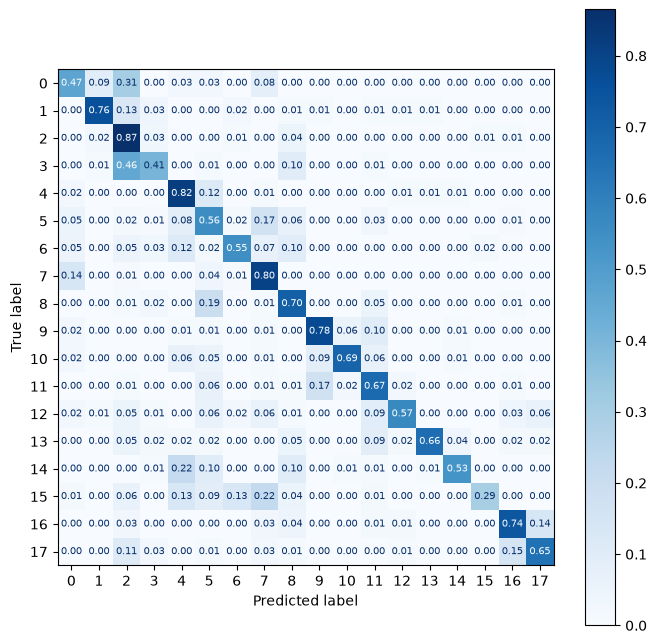

In [ ]:
# Plot the confusion matrix
cm_knn_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_knn)

plt.figure(figsize=(8, 8))

cm_knn_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

Next, we look at LDA classification.

In [ ]:
lda = sklearn.discriminant_analysis.LinearDiscriminantAnalysis()

# Train
lda.fit(X_train_reduced, y_train)

# Predict from test data and evaluate
lda_predictions = lda.predict(X_test_reduced)

print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, lda_predictions))

print("Confusion Matrix")
cm_lda = sklearn.metrics.confusion_matrix(y_test, lda_predictions, normalize='true')
print (cm_lda)

lda_metrics = sklearn.metrics.classification_report(y_test, lda_predictions, output_dict=True)

Evaluation Metrics
              precision    recall  f1-score   support

           0       0.30      0.53      0.38        75
           1       0.87      0.76      0.81        87
           2       0.44      0.69      0.54        89
           3       0.59      0.51      0.54        81
           4       0.61      0.74      0.67        93
           5       0.34      0.37      0.36       108
           6       0.63      0.52      0.57        60
           7       0.58      0.81      0.67       127
           8       0.55      0.68      0.61        88
           9       0.72      0.63      0.67        89
          10       0.85      0.73      0.79        94
          11       0.67      0.44      0.53        82
          12       0.68      0.50      0.58        86
          13       0.83      0.70      0.76        56
          14       0.79      0.57      0.66        79
          15       0.56      0.29      0.38        68
          16       0.65      0.58      0.61        72
        

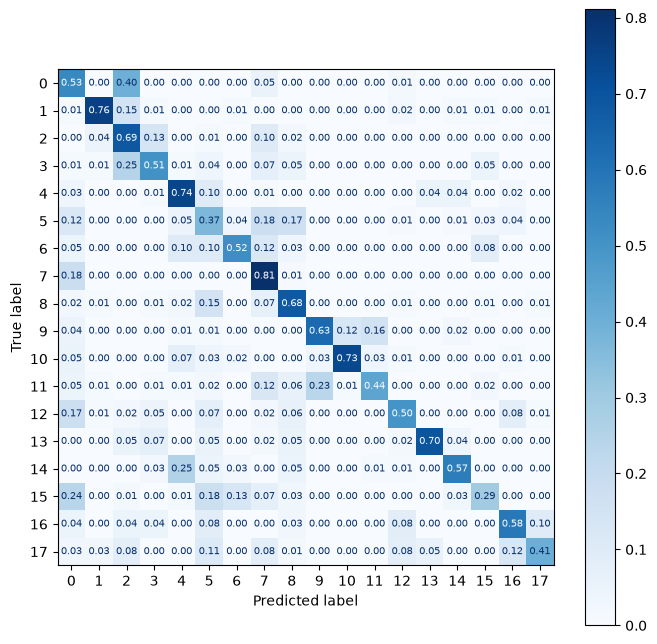

In [ ]:
# Plot the confusion matrix
cm_lda_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_lda)

plt.figure(figsize=(8, 8))

cm_lda_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

Finally, we look at random forest classification.

In [ ]:
rf_parameters = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 20],
    "max_features": ["sqrt", "log2"],
}

rf = sklearn.model_selection.GridSearchCV(
    sklearn.ensemble.RandomForestClassifier(random_state=58),
    rf_parameters, cv=4, scoring='accuracy'
)

rf.fit(X_train_reduced, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=58)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2'], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

In [ ]:
print("Best Parameters Found:", rf.best_params_)
print("Best CV Score:", rf.best_score_)

Best Parameters Found: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 200}
Best CV Score: 0.6039685347078343


In [ ]:
# Predict from test data and evaluate
rf_predictions = rf.predict(X_test_reduced)

print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, rf_predictions))

print("Confusion Matrix")
cm_rf = sklearn.metrics.confusion_matrix(y_test, rf_predictions, normalize='true')
print(cm_rf)

rf_metrics = sklearn.metrics.classification_report(y_test, rf_predictions, output_dict=True)

Evaluation Metrics
              precision    recall  f1-score   support

           0       0.45      0.17      0.25        75
           1       0.77      0.80      0.79        87
           2       0.39      0.79      0.52        89
           3       0.59      0.40      0.47        81
           4       0.58      0.78      0.67        93
           5       0.55      0.46      0.50       108
           6       0.79      0.50      0.61        60
           7       0.76      0.91      0.83       127
           8       0.55      0.78      0.64        88
           9       0.74      0.79      0.77        89
          10       0.92      0.77      0.84        94
          11       0.56      0.70      0.62        82
          12       0.72      0.55      0.62        86
          13       0.82      0.73      0.77        56
          14       0.94      0.73      0.82        79
          15       0.78      0.41      0.54        68
          16       0.62      0.65      0.64        72
        

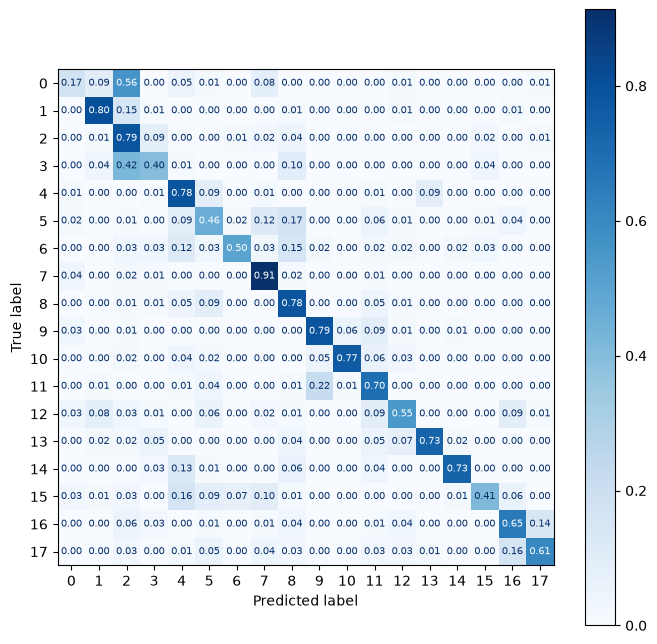

In [ ]:
# Plot the confusion matrix
cm_rf_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_rf)

plt.figure(figsize=(8, 8))

cm_rf_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

Now, we will compare the effect of using the spectrograms for classification against using the RMS of the signal as the feature for classification. We will implement, train, and evaluate each type of classifier above using the RMS data.

In [ ]:
# 1. SVM

# Train
svm_rms = sklearn.model_selection.GridSearchCV(
    sklearn.svm.SVC(kernel='rbf'),
    svm_parameters, cv=4, scoring='accuracy'
) # we will use the same parameters from above

svm_rms.fit(X_train_rms, y_train)

print("Best Parameters Found:", svm_rms.best_params_)
print("Best CV Score:", svm_rms.best_score_)

# Predict
svm_rms_predictions = svm_rms.predict(X_test_rms)

# Evaluate
print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, svm_rms_predictions))

print("Confusion Matrix")
cm_svm_rms = sklearn.metrics.confusion_matrix(y_test, svm_rms_predictions, normalize='true')
print (cm_svm_rms)

# Save the evaluation metrics to a dictionary for later comparison
svm_rms_metrics = sklearn.metrics.classification_report(y_test, svm_rms_predictions, output_dict=True)

# Plot the confusion matrix
cm_svm_rms_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_svm_rms)

plt.figure(figsize=(8, 8))

cm_svm_rms_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

In [ ]:
# 2. kNN

# Train
knn_rms = sklearn.model_selection.GridSearchCV(
    sklearn.neighbors.KNeighborsClassifier(),
    knn_parameters, cv=4, scoring='accuracy'
)

knn_rms.fit(X_train_rms, y_train)

print("Best Parameters Found:", knn_rms.best_params_)
print("Best CV Score:", knn_rms.best_score_)

# Predict
knn_rms_predictions = knn_rms.predict(X_test_rms)

# Evaluate
print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, knn_rms_predictions))

print("Confusion Matrix")
cm_knn_rms = sklearn.metrics.confusion_matrix(y_test, knn_rms_predictions, normalize='true')
print(cm_knn_rms)

knn_rms_metrics = sklearn.metrics.classification_report(y_test, knn_rms_predictions, output_dict=True)

# Plot the confusion matrix
cm_knn_rms_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_knn_rms)

plt.figure(figsize=(8, 8))

cm_knn_rms_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

In [ ]:
# 3. LDA
lda_rms = sklearn.discriminant_analysis.LinearDiscriminantAnalysis()

# Train
lda_rms.fit(X_train_rms, y_train)

# Predict
lda_rms_predictions = lda_rms.predict(X_test_rms)

# Evaluate
print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, lda_rms_predictions))

print("Confusion Matrix")
cm_lda_rms = sklearn.metrics.confusion_matrix(y_test, lda_rms_predictions, normalize='true')
print(cm_lda_rms)

lda_rms_metrics = sklearn.metrics.classification_report(y_test, lda_rms_predictions, output_dict=True)

# Plot the confusion matrix
cm_lda_rms_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_lda_rms)

plt.figure(figsize=(8, 8))

cm_lda_rms_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()

In [ ]:
# 4. RF

# Train
rf_rms = sklearn.model_selection.GridSearchCV(
    sklearn.ensemble.RandomForestClassifier(random_state=58),
    rf_parameters, cv=4, scoring='accuracy'
)

rf_rms.fit(X_train_rms, y_train)

print("Best Parameters Found:", rf_rms.best_params_)
print("Best CV Score:", rf_rms.best_score_)

# Predict
rf_rms_predictions = rf_rms.predict(X_test_rms)

# Evaluate
print("Evaluation Metrics")
print(sklearn.metrics.classification_report(y_test, rf_rms_predictions))

print("Confusion Matrix")
cm_rf_rms = sklearn.metrics.confusion_matrix(y_test, rf_rms_predictions, normalize='true')
print(cm_rf_rms)

rf_rms_metrics = sklearn.metrics.classification_report(y_test, rf_rms_predictions, output_dict=True)

# Plot the confusion matrix
cm_rf_rms_disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm_rf_rms)

plt.figure(figsize=(8, 8))

cm_rf_rms_disp.plot(cmap='Blues', values_format='.2f', ax=plt.gca(), text_kw={'size': 7})

plt.show()